# Capstone — mirrors your deployed research paper

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/alemjarebica-cloud/ML-flyrank-AlemJ/blob/main/work/notebooks/capstone.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. Question

*The research question and the decision it supports.*

**Research question.** For pages that were already visible in search, which signals that are known *before* a 30-day window are associated with earning clicks *in* that window, and do content properties (length, intent, content type, keyword statistics) add anything beyond a page's own recent search history?

**Decision it supports.** A FlyRank editor has limited time. This work says what to look at first when building a review queue, and which content properties are *not* worth ranking pages by.

**Unit of analysis:** one page (pseudonymised `content_id`). **Output:** a signal report (importance + visibility-adjusted associations) and a ranked list of recommendations.


In [13]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.
import os, json, warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import GroupKFold, KFold
from sklearn.metrics import roc_auc_score, average_precision_score

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)

CANDIDATES = [
    "data/raw/content_refresh_anonymized.csv",
    "../data/raw/content_refresh_anonymized.csv",
    "../../data/raw/content_refresh_anonymized.csv",
]
RAW_URL = "https://raw.githubusercontent.com/alemjarebica-cloud/ML-flyrank-alemj/main/data/raw/content_refresh_anonymized.csv"
path = next((p for p in CANDIDATES if os.path.exists(p)), None)
df = pd.read_csv(path if path else RAW_URL)
print("loaded from:", path if path else "GitHub raw URL")
print("shape:", df.shape, "| clients:", df["client_id"].nunique())

if os.path.exists("work"):                      # running from the repo root
    FIG_DIR = "work/figures"
elif os.path.exists("../README.md") and os.path.basename(os.getcwd()) == "notebooks":
    FIG_DIR = "../figures"                      # running from work/notebooks
else:                                           # e.g. Colab without the repo
    FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

# colour-blind-safe palette used in every chart
BLUE, ORANGE, GREEN, RED, GREY = "#0072B2", "#E69F00", "#009E73", "#D55E00", "#6b7280"
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "figure.dpi": 100})
import sklearn
RESULTS = {"env": {"python_libs": {"pandas": pd.__version__, "numpy": np.__version__,
                                    "scikit-learn": sklearn.__version__, "matplotlib": matplotlib.__version__},
                   "seed": SEED}}

loaded from: GitHub raw URL
shape: (30000, 44) | clients: 32


## 2. Data

*Which release, which tables, date windows, what you excluded and why. Public-safe.*

In [14]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.
# Time windows, eligibility and label
# The 90-day total is split into three non-overlapping windows:
#   early (days 61-90 back)  = 90d total - last 30d - prev 30d   (derived)
#   prev  (days 31-60 back)  = *_prev_30d
#   label (last 30 days)     = *_last_30d
df["imp_early"] = df["impressions_90d"] - df["impressions_last_30d"] - df["impressions_prev_30d"]
df["clk_early"] = df["clicks_90d"] - df["clicks_last_30d"] - df["clicks_prev_30d"]
assert (df["imp_early"] >= 0).all() and (df["clk_early"] >= 0).all(), "window arithmetic broke"

# click-through of the previous window, as a percentage (NaN when there were no impressions)
df["ctr_prev"] = df["clicks_prev_30d"] / df["impressions_prev_30d"].where(df["impressions_prev_30d"] > 0) * 100

# Eligible = page was already visible in the previous window (>= 1 impression)
eligible = df["impressions_prev_30d"] >= 1
el = df[eligible].copy().reset_index(drop=True)

LABEL_THR = 3  # label: page earned >= 3 search clicks in the last 30 days
el["y"] = (el["clicks_last_30d"] >= LABEL_THR).astype(int)

# Visibility group = impressions in the previous window, three equal-size groups (used in later sections)
el["vis"] = pd.qcut(el["impressions_prev_30d"].rank(method="first"), 3, labels=["low", "mid", "high"])

per_client = el.groupby("client_id").size().sort_values(ascending=False)
print(f"all pages: {len(df):,} | not visible in prev window (excluded): {(~eligible).sum():,} | eligible: {len(el):,}")
print(f"eligible clients: {el['client_id'].nunique()} | rows per client: min {per_client.min()}, median {int(per_client.median())}, max {per_client.max()}")
print(f"largest client share of eligible rows: {per_client.iloc[0] / len(el):.1%}")
print(f"label base rate (>= {LABEL_THR} clicks in last 30d): {el['y'].mean():.1%}")
print()
print("Label base rate for other thresholds (sensitivity):")
for thr in [1, 3, 5, 10]:
    print(f"  >= {thr:>2} clicks: {(el['clicks_last_30d'] >= thr).mean():.1%}")

print()
print("Missing share of candidate features among eligible pages:")
for c in ["search_volume", "competition", "cpc", "competition_level", "main_intent", "word_count", "sessions_prev_30d"]:
    print(f"  {c:<18} {el[c].isna().mean():.1%}")
print("sessions_prev_30d == 0 share:", f"{(el['sessions_prev_30d'] == 0).mean():.1%}")

RESULTS["data"] = {
    "n_total": int(len(df)), "n_excluded": int((~eligible).sum()), "n_eligible": int(len(el)),
    "n_clients": int(el["client_id"].nunique()), "base_rate": float(el["y"].mean()),
    "largest_client_share": float(per_client.iloc[0] / len(el)),
    "median_rows_per_client": int(per_client.median()),
    "rate_thr": {str(t): float((el["clicks_last_30d"] >= t).mean()) for t in [1, 3, 5, 10]},
}

all pages: 30,000 | not visible in prev window (excluded): 3,388 | eligible: 26,612
eligible clients: 31 | rows per client: min 2, median 473, max 6983
largest client share of eligible rows: 26.2%
label base rate (>= 3 clicks in last 30d): 24.9%

Label base rate for other thresholds (sensitivity):
  >=  1 clicks: 43.1%
  >=  3 clicks: 24.9%
  >=  5 clicks: 18.6%
  >= 10 clicks: 11.5%

Missing share of candidate features among eligible pages:
  search_volume      5.0%
  competition        5.0%
  cpc                5.0%
  competition_level  5.5%
  main_intent        4.6%
  word_count         28.0%
  sessions_prev_30d  0.0%
sessions_prev_30d == 0 share: 17.8%


**Release:** the 30,000-row anonymised starter slice that ships in this repo (`data/raw/content_refresh_anonymized.csv`), one row per page, trailing-90-day metrics. It is *not* the full warehouse (see the Limitations).

**Three non-overlapping time windows** are rebuilt from columns already in the file:

```text
days back:   90 ............ 61 | 60 ............ 31 | 30 ............ 0
window:        early (derived)   |   previous window  |   label window
columns:   90d total - last30 - prev30 |  *_prev_30d    |   *_last_30d
```

**Eligible pages:** pages with at least one impression in the previous window. Pages with none (3,388) have no search history to learn from and are excluded; this includes brand-new pages.

**Label:** the page earned **3 or more search clicks in the last 30 days** (24.9% of eligible pages). The threshold is a choice, so the notebook re-runs the comparison at 1 and 10 clicks.

**Public-safe:** only pseudonymised IDs exist; IDs are used for grouping only, never as features. No client names, domains, URLs or queries appear anywhere.

## 3. Methodology

*Assumptions, features, label definition, baseline, validation design, leakage checks.*

**Assumption.** A feature is allowed only if it was fully known before the label window starts. Any column that contains the last 30 days, directly or inside a 90-day total, is excluded.

**Features (14).**
- *Prior-search signals (6):* impressions, clicks and sessions of the previous window; impressions and clicks of the early window; previous-window click-through rate.
- *Content signals (8):* word count, content age, keyword search volume, competition score, CPC, content type, search intent, competition level. Missing values are left as missing (the model handles them), because missingness follows content type.

**Excluded on purpose (33 columns):** the label window itself, 90-day aggregates (CTR, position, sessions, engagement...), `trend_pct` / `trend_direction` (built from the label window), update-recency columns (timing is ambiguous, see Limitations), duplicates of kept columns, mostly-missing model columns, and IDs. The code prints the full list and asserts that none is a feature.

**Baseline (B1):** rank pages by their own clicks in the previous window. It is a transparent rule with no training.

**Models (M1-M3):** the same gradient-boosting classifier with fixed settings (no tuning) on three feature sets: prior-search only (M1), content only (M2), both (M3). The question "does content add anything?" is answered by M3 vs M1.

**Validation design.** Five-fold **grouped** split: whole clients are held out, so a model is always tested on clients it never saw. All models and the baseline use the *same* folds. We report AUC, average precision and precision in the top 10% of ranked pages, always next to the base rate.

**Leakage checks (run in section 4):** assertion that no excluded column is used; a deliberately leaky model (must jump towards 1.0); random vs grouped split; label-threshold sensitivity.


In [15]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.
# Feature sets, exclusions and leakage guard
PRIOR_FEATS = ["impressions_prev_30d", "clicks_prev_30d", "sessions_prev_30d",
               "imp_early", "clk_early", "ctr_prev"]
CONTENT_NUM = ["search_volume", "competition", "cpc", "word_count", "content_age_days"]
CONTENT_CAT = ["content_type", "main_intent", "competition_level"]
CONTENT_FEATS = CONTENT_NUM + CONTENT_CAT
FULL_FEATS = PRIOR_FEATS + CONTENT_FEATS

EXCLUDED = {
    "label window itself": ["clicks_last_30d", "impressions_last_30d", "sessions_last_30d"],
    "90-day aggregates that contain the label window": [
        "clicks_90d", "impressions_90d", "ctr", "avg_position", "pageviews_90d", "sessions_90d",
        "users_90d", "engaged_sessions_90d", "engagement_rate", "scroll_events_90d", "scroll_rate",
        "ai_sessions_90d", "ai_traffic_pct", "days_with_impressions", "days_with_sessions",
        "impression_tier", "position_tier"],
    "computed from last-30 vs prev-30 impressions": ["trend_pct", "trend_direction"],
    "update timing ambiguous (measured at export)": ["days_since_last_update", "freshness_tier"],
    "duplicates of a kept column": ["char_count", "word_count_tier", "char_count_tier", "age_tier", "age_tier_order"],
    "mostly missing / not intended as features": ["provider_used", "model_used"],
    "pseudonymous IDs (grouping only)": ["content_id", "client_id"],
}
excluded_flat = [c for cols in EXCLUDED.values() for c in cols]
overlap = set(FULL_FEATS) & set(excluded_flat)
assert not overlap, f"excluded column used as feature: {overlap}"
assert not any(c in FULL_FEATS for c in ["trend_pct", "trend_direction", "is_declining_label", "clicks_last_30d"])
print("Leakage guard passed: no excluded column is a feature.")
print(f"prior-search features ({len(PRIOR_FEATS)}):", PRIOR_FEATS)
print(f"content features ({len(CONTENT_FEATS)}):", CONTENT_FEATS)
print()
for reason, cols in EXCLUDED.items():
    print(f"excluded - {reason}: {len(cols)} columns")

# Helpers --------------------------------------------------------------------
def make_X(d, feats):
    X = d[feats].copy()
    for c in feats:
        if c in CONTENT_CAT:
            X[c] = X[c].astype("category")
    return X

def new_model():
    return HistGradientBoostingClassifier(max_depth=4, learning_rate=0.05, max_iter=200,
                                          min_samples_leaf=50, l2_regularization=1.0,
                                          categorical_features="from_dtype", random_state=SEED)

def precision_at_top(y, s, frac=0.10):
    y, s = np.asarray(y), np.asarray(s)
    k = max(1, int(len(y) * frac))
    idx = np.argsort(-s, kind="mergesort")[:k]
    return float(y[idx].mean())

def score_fold(y, s):
    base = float(np.mean(y))
    p10 = precision_at_top(y, s)
    return {"auc": float(roc_auc_score(y, s)), "ap": float(average_precision_score(y, s)),
            "p10": p10, "base": base, "lift10": p10 / base}

# One fixed grouped split, reused by EVERY model so comparisons are like-for-like
group_folds = list(GroupKFold(n_splits=5).split(el, el["y"], el["client_id"]))
print()
print("Grouped 5-fold split (whole clients held out):")
for i, (tr, te) in enumerate(group_folds, 1):
    print(f"  fold {i}: train {len(tr):>6,} rows | test {len(te):>6,} rows, {el.iloc[te]['client_id'].nunique():>2} clients | test base rate {el.iloc[te]['y'].mean():.1%}")
    assert not set(el.iloc[tr]["client_id"]) & set(el.iloc[te]["client_id"]), "client in both train and test"

def cv_model(feats, folds=group_folds, d=None):
    d = el if d is None else d
    X = make_X(d, feats)
    out = []
    for tr, te in folds:
        m = new_model().fit(X.iloc[tr], d["y"].iloc[tr])
        out.append(score_fold(d["y"].iloc[te], m.predict_proba(X.iloc[te])[:, 1]))
    return out

def cv_rule(score, folds=group_folds, d=None):
    d = el if d is None else d
    return [score_fold(d["y"].iloc[te], np.asarray(score)[te]) for _, te in folds]



Leakage guard passed: no excluded column is a feature.
prior-search features (6): ['impressions_prev_30d', 'clicks_prev_30d', 'sessions_prev_30d', 'imp_early', 'clk_early', 'ctr_prev']
content features (8): ['search_volume', 'competition', 'cpc', 'word_count', 'content_age_days', 'content_type', 'main_intent', 'competition_level']

excluded - label window itself: 3 columns
excluded - 90-day aggregates that contain the label window: 17 columns
excluded - computed from last-30 vs prev-30 impressions: 2 columns
excluded - update timing ambiguous (measured at export): 2 columns
excluded - duplicates of a kept column: 5 columns
excluded - mostly missing / not intended as features: 2 columns
excluded - pseudonymous IDs (grouping only): 2 columns

Grouped 5-fold split (whole clients held out):
  fold 1: train 19,629 rows | test  6,983 rows,  1 clients | test base rate 29.5%
  fold 2: train 21,706 rows | test  4,906 rows,  7 clients | test base rate 34.9%
  fold 3: train 21,706 rows | test  4,

## 4. Results (vs baseline)

*Model vs baseline on the same split. The honest table.*

The table below is the honest comparison. Read it against the *no-skill* line printed first: AUC 0.5 and a precision equal to the base rate.


Reference (no skill): AUC 0.500 | average precision = base rate 0.245 | precision@top-10% = base rate 0.245

model                                                      AUC     avg.prec.   prec@top10%  lift@10%
B1 persistence rule (rank by prev-30d clicks)      0.958+-0.011   0.903+-0.022   0.965+-0.055     4.36x
M1 prior-search model                              0.964+-0.009   0.913+-0.023   0.967+-0.052     4.37x
M2 content-only model                              0.589+-0.059   0.308+-0.114   0.314+-0.197     1.22x
M3 prior-search + content model                    0.964+-0.009   0.911+-0.023   0.964+-0.053     4.36x

Paired per-fold AUC differences (positive = first is better):
  M1 - B1: mean +0.0055 | per fold [0.005, 0.0083, 0.0062, 0.0048, 0.0032] | folds where first is better: 5/5
  M3 - M1: mean -0.0002 | per fold [0.0005, 0.0007, -0.0008, -0.0017, 0.0004] | folds where first is better: 3/5
  M3 - B1: mean +0.0053 | per fold [0.0055, 0.009, 0.0054, 0.0031, 0.0035] | folds where

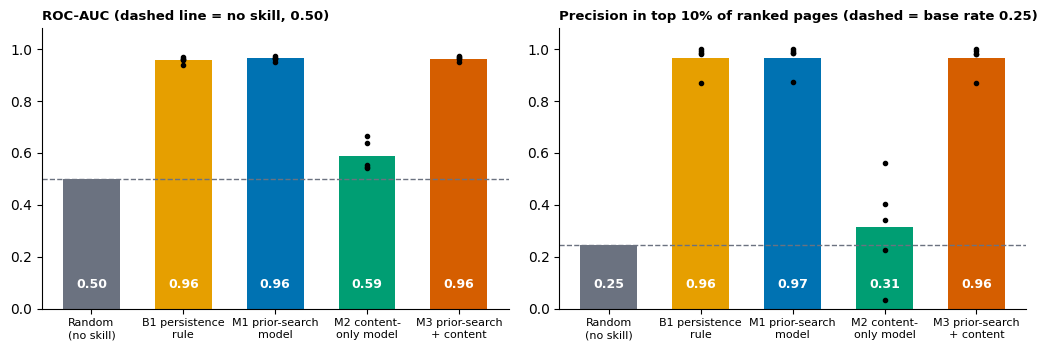

In [16]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.
# Model vs baselines on the SAME grouped split
persist_score = el["clicks_prev_30d"] + el["impressions_prev_30d"] * 1e-9   # tie-break by impressions
res = {
    "B1 persistence rule (rank by prev-30d clicks)": cv_rule(persist_score),
    "M1 prior-search model": cv_model(PRIOR_FEATS),
    "M2 content-only model": cv_model(CONTENT_FEATS),
    "M3 prior-search + content model": cv_model(FULL_FEATS),
}

def summarize(folds, key):
    v = np.array([f[key] for f in folds])
    return v.mean(), v.std(ddof=1)

base_mean = np.mean([f["base"] for f in res["M3 prior-search + content model"]])
print(f"Reference (no skill): AUC 0.500 | average precision = base rate {base_mean:.3f} | precision@top-10% = base rate {base_mean:.3f}")
print()
print(f"{'model':<48}{'AUC':>14}{'avg.prec.':>14}{'prec@top10%':>14}{'lift@10%':>10}")
for name, folds in res.items():
    a, asd = summarize(folds, "auc"); p, psd = summarize(folds, "ap"); q, qsd = summarize(folds, "p10"); l, _ = summarize(folds, "lift10")
    print(f"{name:<48}{a:>8.3f}+-{asd:.3f}{p:>8.3f}+-{psd:.3f}{q:>8.3f}+-{qsd:.3f}{l:>9.2f}x")

def paired(a, b, key="auc"):
    d = np.array([x[key] for x in res[a]]) - np.array([x[key] for x in res[b]])
    return d
B1, M1, M2, M3 = list(res.keys())
print()
print("Paired per-fold AUC differences (positive = first is better):")
for a, b in [(M1, B1), (M3, M1), (M3, B1)]:
    d = paired(a, b)
    print(f"  {a[:2]} - {b[:2]}: mean {d.mean():+.4f} | per fold {np.round(d, 4).tolist()} | folds where first is better: {(d > 0).sum()}/5")

RESULTS["models"] = {k[:2]: {"name": k,
                             "auc": [f["auc"] for f in v], "ap": [f["ap"] for f in v],
                             "p10": [f["p10"] for f in v], "lift10": [f["lift10"] for f in v],
                             "base": [f["base"] for f in v]} for k, v in res.items()}

# Figure 1 - model comparison
fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.6))
labels = ["Random\n(no skill)", "B1 persistence\nrule", "M1 prior-search\nmodel", "M2 content-\nonly model", "M3 prior-search\n+ content"]
colors = [GREY, ORANGE, BLUE, GREEN, RED]
auc_means = [0.5] + [summarize(res[k], "auc")[0] for k in res]
p_means = [base_mean] + [summarize(res[k], "p10")[0] for k in res]
for a, vals, ttl, ref in [(ax[0], auc_means, "ROC-AUC (dashed line = no skill, 0.50)", 0.5),
                          (ax[1], p_means, f"Precision in top 10% of ranked pages (dashed = base rate {base_mean:.2f})", base_mean)]:
    a.bar(range(5), vals, color=colors, width=0.62)
    a.axhline(ref, color=GREY, ls="--", lw=1)
    a.set_xticks(range(5)); a.set_xticklabels(labels, fontsize=8)
    a.set_title(ttl, fontsize=9.5, loc="left")
    for i, v in enumerate(vals):
        a.text(i, 0.08, f"{v:.2f}", ha="center", fontsize=9, color="white", fontweight="bold")
    a.set_ylim(0, 1.08)
for i, k in enumerate(res):
    ax[0].scatter([i + 1] * 5, [f["auc"] for f in res[k]], color="black", s=9, zorder=3)
    ax[1].scatter([i + 1] * 5, [f["p10"] for f in res[k]], color="black", s=9, zorder=3)
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/fig1_model_comparison.png", dpi=160, bbox_inches="tight", facecolor="white")
plt.show()



If the test harness works, adding a column that contains the label window should push AUC close to 1.0, and a random split should flatter any model that can recognise a client from its content style.


M3 grouped (honest)                            AUC 0.964
M3 + clicks_90d (contains label window)        AUC 0.998
M3 + ctr (contains label window)               AUC 0.984
M2 content-only, grouped (honest)              AUC 0.589
M2 content-only, RANDOM split                  AUC 0.755
M3 RANDOM split                                AUC 0.967

Reading: a leaky column should push AUC toward 1.0 (the harness detects leakage);
random vs grouped gap for the content-only model shows how much was client memorisation.

Label threshold sensitivity (mean grouped AUC):
  >=  1 clicks (base 43.1%): B1 0.907 | M1 0.917 | M2 0.561 | M3 0.916
  >=  3 clicks (base 24.9%): B1 0.958 | M1 0.964 | M2 0.589 | M3 0.964
  >= 10 clicks (base 11.5%): B1 0.982 | M1 0.982 | M2 0.598 | M3 0.982


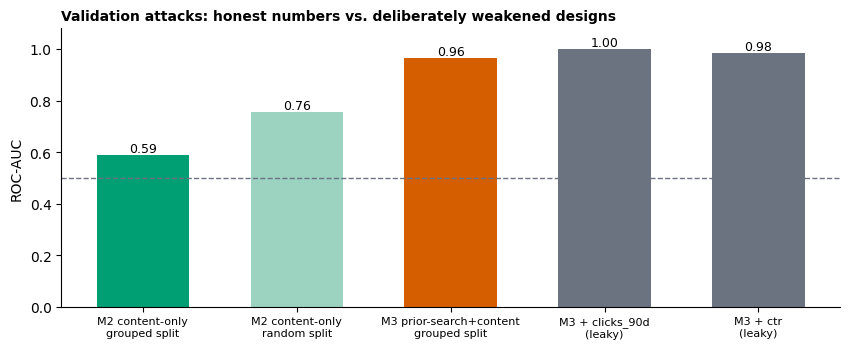

In [17]:
# Attack our own result: leaky variant, random vs grouped split, label threshold
rand_folds = list(KFold(n_splits=5, shuffle=True, random_state=SEED).split(el))

def mean_auc(folds):
    return float(np.mean([f["auc"] for f in folds]))

checks = {}
checks["M3 grouped (honest)"] = mean_auc(res[M3])
checks["M3 + clicks_90d (contains label window)"] = mean_auc(cv_model(FULL_FEATS + ["clicks_90d"]))
checks["M3 + ctr (contains label window)"] = mean_auc(cv_model(FULL_FEATS + ["ctr"]))
checks["M2 content-only, grouped (honest)"] = mean_auc(res[M2])
checks["M2 content-only, RANDOM split"] = mean_auc(cv_model(CONTENT_FEATS, folds=rand_folds))
checks["M3 RANDOM split"] = mean_auc(cv_model(FULL_FEATS, folds=rand_folds))
for k, v in checks.items():
    print(f"{k:<46} AUC {v:.3f}")
print()
print("Reading: a leaky column should push AUC toward 1.0 (the harness detects leakage);")
print("random vs grouped gap for the content-only model shows how much was client memorisation.")

# label-threshold sensitivity (grouped split)
print()
print("Label threshold sensitivity (mean grouped AUC):")
thr_rows = {}
for thr in [1, 3, 10]:
    d2 = el.copy()
    d2["y"] = (d2["clicks_last_30d"] >= thr).astype(int)
    f2 = list(GroupKFold(n_splits=5).split(d2, d2["y"], d2["client_id"]))
    row = {"base_rate": float(d2["y"].mean()),
           "B1": mean_auc(cv_rule(persist_score, folds=f2, d=d2)),
           "M1": mean_auc(cv_model(PRIOR_FEATS, folds=f2, d=d2)),
           "M2": mean_auc(cv_model(CONTENT_FEATS, folds=f2, d=d2)),
           "M3": mean_auc(cv_model(FULL_FEATS, folds=f2, d=d2))}
    thr_rows[str(thr)] = row
    print(f"  >= {thr:>2} clicks (base {row['base_rate']:.1%}): B1 {row['B1']:.3f} | M1 {row['M1']:.3f} | M2 {row['M2']:.3f} | M3 {row['M3']:.3f}")

RESULTS["leakage"] = {"checks": checks, "thr": thr_rows}

# Figure 2 - validation checks
fig, ax = plt.subplots(figsize=(8.6, 3.6))
names = ["M2 content-only\ngrouped split", "M2 content-only\nrandom split", "M3 prior-search+content\ngrouped split",
         "M3 + clicks_90d\n(leaky)", "M3 + ctr\n(leaky)"]
vals = [checks["M2 content-only, grouped (honest)"], checks["M2 content-only, RANDOM split"],
        checks["M3 grouped (honest)"], checks["M3 + clicks_90d (contains label window)"], checks["M3 + ctr (contains label window)"]]
cols = [GREEN, "#9bd3c0", RED, GREY, GREY]
ax.bar(range(5), vals, color=cols, width=0.6)
ax.axhline(0.5, color=GREY, ls="--", lw=1)
for i, v in enumerate(vals):
    ax.text(i, v + 0.012, f"{v:.2f}", ha="center", fontsize=9)
ax.set_xticks(range(5)); ax.set_xticklabels(names, fontsize=8)
ax.set_ylim(0, 1.08); ax.set_ylabel("ROC-AUC")
ax.set_title("Validation attacks: honest numbers vs. deliberately weakened designs", loc="left", fontsize=10)
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/fig2_validation_checks.png", dpi=160, bbox_inches="tight", facecolor="white")
plt.show()


Two extra checks. First, a second question that removes the "big pages stay big" effect: among pages visible in both windows, does the page's click-through rate in the last 30 days beat its own client's median? Second, the AUC *inside* each visibility group, plus whether content helps in the same direction across the held-out folds.



In [18]:
# Robustness question: does the conclusion hold when we condition on visibility?
# Population: pages visible in BOTH windows. Label: click-through in last 30 days above the page's own client median.
q = df[(df["impressions_prev_30d"] >= 300) & (df["impressions_last_30d"] >= 100)].copy().reset_index(drop=True)
q["ctr_last"] = q["clicks_last_30d"] / q["impressions_last_30d"] * 100
q["ctr_early"] = q["clk_early"] / q["imp_early"].where(q["imp_early"] > 0) * 100
q["y"] = (q["ctr_last"] > q.groupby("client_id")["ctr_last"].transform("median")).astype(int)
Q2_PRIOR = ["ctr_prev", "ctr_early", "impressions_prev_30d", "imp_early"]
q_folds = list(GroupKFold(n_splits=5).split(q, q["y"], q["client_id"]))
print(f"population: {len(q):,} pages, {q['client_id'].nunique()} clients | base rate {q['y'].mean():.1%} (balanced by construction)")

def q_cv(feats):
    X = make_X(q, feats)
    out = []
    for tr, te in q_folds:
        m = new_model().fit(X.iloc[tr], q["y"].iloc[tr])
        out.append(roc_auc_score(q["y"].iloc[te], m.predict_proba(X.iloc[te])[:, 1]))
    return np.array(out)

q_res = {"B1 persistence (rank by prev-window CTR)": np.array([roc_auc_score(q["y"].iloc[te], q["ctr_prev"].iloc[te]) for _, te in q_folds]),
         "M1 prior-search model": q_cv(Q2_PRIOR),
         "M2 content-only model": q_cv(CONTENT_FEATS),
         "M3 prior-search + content model": q_cv(Q2_PRIOR + CONTENT_FEATS)}
for k, v in q_res.items():
    print(f"{k:<44} AUC {v.mean():.3f}+-{v.std(ddof=1):.3f} | folds {np.round(v, 3).tolist()}")
RESULTS["q2"] = {"n": int(len(q)), "clients": int(q["client_id"].nunique()),
                 "auc": {k[:2]: [float(x) for x in v] for k, v in q_res.items()}}



population: 13,026 pages, 28 clients | base rate 49.8% (balanced by construction)
B1 persistence (rank by prev-window CTR)     AUC 0.767+-0.023 | folds [0.787, 0.783, 0.751, 0.735, 0.78]
M1 prior-search model                        AUC 0.800+-0.020 | folds [0.819, 0.825, 0.792, 0.78, 0.786]
M2 content-only model                        AUC 0.547+-0.031 | folds [0.587, 0.514, 0.572, 0.53, 0.534]
M3 prior-search + content model              AUC 0.797+-0.018 | folds [0.816, 0.815, 0.794, 0.777, 0.784]


In [19]:
# Does content help where the outcome is genuinely uncertain? AUC inside each visibility group
# (out-of-fold predictions from the same grouped split, pooled within the group)
def oof_scores(feats):
    X = make_X(el, feats)
    s = np.zeros(len(el))
    for tr, te in group_folds:
        m = new_model().fit(X.iloc[tr], el["y"].iloc[tr])
        s[te] = m.predict_proba(X.iloc[te])[:, 1]
    return s

oof = {"B1": persist_score.values, "M1": oof_scores(PRIOR_FEATS), "M2": oof_scores(CONTENT_FEATS), "M3": oof_scores(FULL_FEATS)}
within = {}
print("AUC within visibility group (pooled out-of-fold):")
print(f"{'group':<8}{'rows':>8}{'base rate':>11}{'B1':>8}{'M1':>8}{'M2':>8}{'M3':>8}")
for v in ["low", "mid", "high"]:
    mask = (el["vis"] == v).values
    yv = el["y"].values[mask]
    row = {k: float(roc_auc_score(yv, sc[mask])) for k, sc in oof.items()}
    within[v] = {"rows": int(mask.sum()), "base": float(yv.mean()), **row}
    print(f"{v:<8}{mask.sum():>8,}{yv.mean():>11.3f}{row['B1']:>8.3f}{row['M1']:>8.3f}{row['M2']:>8.3f}{row['M3']:>8.3f}")

# Is the content gain inside a group stable across held-out folds? (per-fold M3 - M1 AUC)
fold_gain = {}
for v in ["low", "mid", "high"]:
    gains = []
    for tr, te in group_folds:
        sel = te[(el["vis"].iloc[te] == v).values]
        yy = el["y"].values[sel]
        if yy.min() == yy.max() or yy.sum() < 10:
            continue
        gains.append(roc_auc_score(yy, oof["M3"][sel]) - roc_auc_score(yy, oof["M1"][sel]))
    fold_gain[v] = [float(g) for g in gains]
    if gains:
        print(f"{v:<5} M3 - M1 per-fold AUC gain: {np.round(gains, 3).tolist()} | positive in {sum(g > 0 for g in gains)} of {len(gains)} usable folds")
    else:
        print(f"{v:<5} too few positives per fold to evaluate")
RESULTS["within_vis"] = within
RESULTS["within_vis_fold_gain"] = fold_gain

AUC within visibility group (pooled out-of-fold):
group       rows  base rate      B1      M1      M2      M3
low        8,871      0.005   0.760   0.766   0.482   0.807
mid        8,870      0.085   0.834   0.832   0.582   0.849
high       8,871      0.658   0.897   0.901   0.540   0.899
low   M3 - M1 per-fold AUC gain: [-0.028, 0.056] | positive in 1 of 2 usable folds
mid   M3 - M1 per-fold AUC gain: [0.006, 0.002, 0.002, -0.006, 0.005] | positive in 4 of 5 usable folds
high  M3 - M1 per-fold AUC gain: [0.001, -0.001, -0.006, -0.007, -0.002] | positive in 1 of 5 usable folds


## 5. Limitations

*What this work cannot claim.*

- **Snapshot, not a deployment test.** All windows come from one export. The "future" window is the last 30 days of the same export, so this is an *association* study, not proof that a model would have predicted next month in production.
- **Starter slice only.** 30,000 pages and 31 usable clients, trailing 90 days. The full warehouse (daily panel, 17 months, dated history) would allow a stricter forward-window design and was not used here.
- **Few, uneven clients.** The largest client holds 26% of eligible pages and forms one whole test fold; some contrasts can only be compared within 2-14 clients.
- **Label is a choice.** The 3-click threshold is arbitrary; the ordering of models is the same at 1 and 10 clicks, but absolute numbers move.
- **Measurement gaps.** 17.8% of eligible pages have zero GA4 sessions in the previous window, which may mean "not measured"; word count is missing for 28% of pages and missingness follows content type.
- **Update recency is not testable here.** 65.6% of pages were updated within 30 days of export, so an update may sit *inside* the label window. Freshness was left out of every model.
- **No causal claims.** Which pages got attention, links or updates was not randomised. The tables describe patterns; they do not say that editing a page will change its clicks.
- **Not about Google's algorithm.** Position and CTR are 90-day aggregates that overlap the label window, so they cannot be predictors; the position table in section 6 is descriptive context only.


In [20]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.
# Numbers behind the limitations (printed so each claim can be checked)
print(f"largest client share of eligible pages: {RESULTS['data']['largest_client_share']:.1%}")
print(f"eligible clients: {RESULTS['data']['n_clients']} | median rows per client: {RESULTS['data']['median_rows_per_client']}")
print(f"zero GA4 sessions in previous window: {(el['sessions_prev_30d'] == 0).mean():.1%} of eligible pages")
print(f"word_count missing: {el['word_count'].isna().mean():.1%} of eligible pages")
fresh = (el['days_since_last_update'] <= 30).mean()
print(f"updated within 30 days of export: {fresh:.1%} (update may fall inside the label window)")
print("excluded because no previous-window impressions:", RESULTS['data']['n_excluded'])
RESULTS["fresh_share_30d"] = float(fresh)


largest client share of eligible pages: 26.2%
eligible clients: 31 | median rows per client: 473
zero GA4 sessions in previous window: 17.8% of eligible pages
word_count missing: 28.0% of eligible pages
updated within 30 days of export: 65.6% (update may fall inside the label window)
excluded because no previous-window impressions: 3388


## 6. Ranked recommendations

*The action playbook output — the paper's recommendations section.*

First the evidence: which features the model uses, then content signals compared **within** the same visibility level, then descriptive context.


Held-out AUC drop when one feature is shuffled (mean over 5 folds x 5 repeats):
             feature  auc_drop_mean  auc_drop_sd        group
     clicks_prev_30d         0.0687       0.0154 prior-search
impressions_prev_30d         0.0276       0.0101 prior-search
           clk_early         0.0154       0.0056 prior-search
            ctr_prev         0.0007       0.0004 prior-search
           imp_early         0.0005       0.0003 prior-search
          word_count         0.0005       0.0005      content
    content_age_days         0.0005       0.0002      content
   sessions_prev_30d         0.0003       0.0003 prior-search
       search_volume         0.0001       0.0002      content
        content_type         0.0000       0.0000      content
                 cpc        -0.0000       0.0001      content
         competition        -0.0000       0.0001      content
   competition_level        -0.0000       0.0001      content
         main_intent        -0.0001       0.0001    

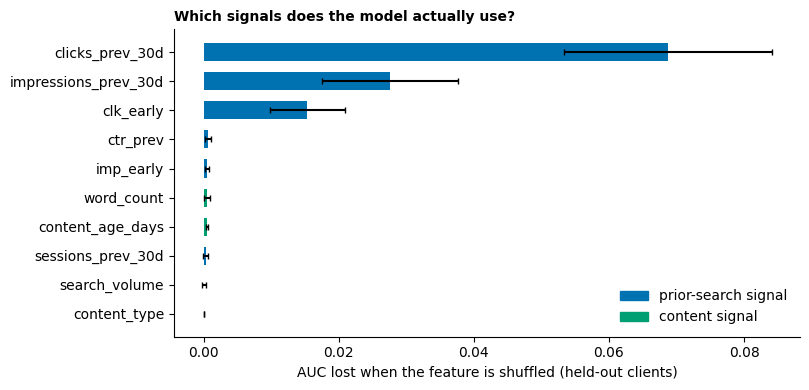

In [21]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.
# Signal report part 1: permutation importance on held-out clients (M3)
rng = np.random.RandomState(SEED)
X_full = make_X(el, FULL_FEATS)
y_all = el["y"].values
N_REP = 5
feat_drop = {f: [] for f in FULL_FEATS}
group_drop = {"prior-search signals (all 6 together)": [], "content signals (all 8 together)": []}

def permuted_auc(m, Xte, yte, cols):
    Xp = Xte.copy()
    idx = rng.permutation(len(Xp))
    for c in cols:
        Xp[c] = Xp[c].iloc[idx].values if str(Xp[c].dtype) != "category" else pd.Categorical(Xp[c].iloc[idx].values, categories=Xp[c].cat.categories)
    return roc_auc_score(yte, m.predict_proba(Xp)[:, 1])

for tr, te in group_folds:
    m = new_model().fit(X_full.iloc[tr], y_all[tr])
    Xte, yte = X_full.iloc[te], y_all[te]
    base_auc = roc_auc_score(yte, m.predict_proba(Xte)[:, 1])
    for f in FULL_FEATS:
        feat_drop[f].append(np.mean([base_auc - permuted_auc(m, Xte, yte, [f]) for _ in range(N_REP)]))
    group_drop["prior-search signals (all 6 together)"].append(np.mean([base_auc - permuted_auc(m, Xte, yte, PRIOR_FEATS) for _ in range(N_REP)]))
    group_drop["content signals (all 8 together)"].append(np.mean([base_auc - permuted_auc(m, Xte, yte, CONTENT_FEATS) for _ in range(N_REP)]))

imp = pd.DataFrame({"feature": FULL_FEATS,
                    "auc_drop_mean": [np.mean(feat_drop[f]) for f in FULL_FEATS],
                    "auc_drop_sd": [np.std(feat_drop[f], ddof=1) for f in FULL_FEATS],
                    "group": ["prior-search" if f in PRIOR_FEATS else "content" for f in FULL_FEATS]}).sort_values("auc_drop_mean", ascending=False)
print("Held-out AUC drop when one feature is shuffled (mean over 5 folds x 5 repeats):")
print(imp.round(4).to_string(index=False))
print()
for g, v in group_drop.items():
    print(f"{g}: AUC drop {np.mean(v):.4f} (sd {np.std(v, ddof=1):.4f})")

RESULTS["importance"] = {"features": imp.round(5).to_dict(orient="records"),
                         "groups": {g: [float(np.mean(v)), float(np.std(v, ddof=1))] for g, v in group_drop.items()}}

# Figure 3
top = imp.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(8.2, 4.0))
ax.barh(top["feature"], top["auc_drop_mean"], xerr=top["auc_drop_sd"],
        color=[BLUE if g == "prior-search" else GREEN for g in top["group"]],
        capsize=2, height=0.62)
ax.set_xlabel("AUC lost when the feature is shuffled (held-out clients)")
ax.set_title("Which signals does the model actually use?", loc="left", fontsize=10)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=BLUE, label="prior-search signal"), Patch(color=GREEN, label="content signal")], frameon=False, loc="lower right")
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/fig3_permutation_importance.png", dpi=160, bbox_inches="tight", facecolor="white")
plt.show()


Visibility groups (impressions in prev 30 days):
      min     max
vis              
low     1     107
mid   107     823
high  823  218786
Label rate by visibility group: {'low': 0.005, 'mid': 0.085, 'high': 0.658}

Share earning >= 3 clicks in the next window, by content_type x visibility:
vis                            low             mid            high
content_type                                                      
comparison article   0.002 (n=571)   0.009 (n=117)       0.0 (n=7)
feedly article       0.009 (n=815)   0.111 (n=153)    0.488 (n=41)
keyword article     0.005 (n=7485)  0.086 (n=8600)  0.659 (n=8823)

Share earning >= 3 clicks in the next window, by intent x visibility:
vis                       low             mid            high
intent                                                       
commercial     0.007 (n=1220)  0.085 (n=1457)  0.668 (n=1501)
informational  0.003 (n=5237)  0.079 (n=5387)  0.648 (n=5382)
navigational        0.0 (n=9)     0.222 (n=9)     0.44

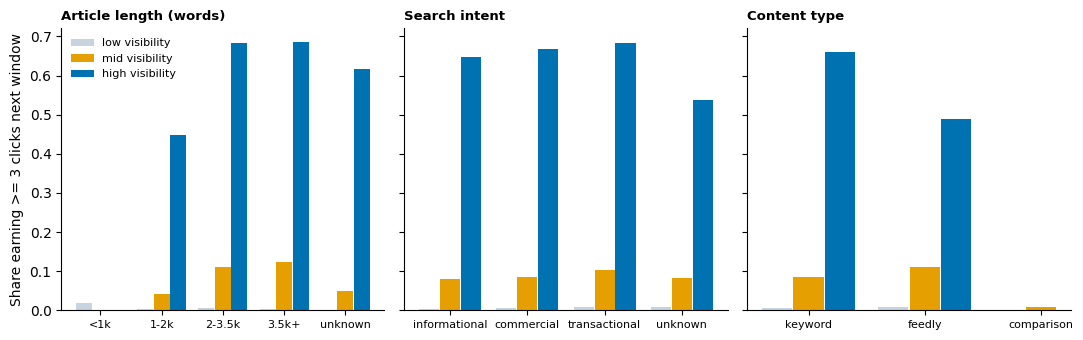

Observed within the same 90-day window (pooled CTR = total clicks / total impressions):
position_tier  pages  median_impressions_90d  pooled_ctr_pct
        top_3   1116                    53.0            0.49
       page_1  11814                  1179.5            0.35
     striking   7304                   874.5            0.35
     page_3_5   7242                   811.5            0.15
         deep   1319                   218.0            0.04
Note: top_3 pages have few impressions (small-sample noise); this table is context, not a model input.

Exploratory - days since last update (measured at export; update may fall inside the label window):
vis               low    mid   high
freshness_tier                     
0-30            0.005  0.088  0.652
181+            0.018  0.083  0.667
31-90           0.000  0.057  0.621
91-180          0.004  0.080  0.666
share of eligible pages updated within 30 days of export: 65.6%


In [22]:
# Signal report part 2: content signals WITHIN comparable visibility levels
# Visibility groups were defined in the data section (impressions in the previous window, three equal-size groups).
edges = el.groupby("vis", observed=True)["impressions_prev_30d"].agg(["min", "max"])
print("Visibility groups (impressions in prev 30 days):")
print(edges.to_string())
print("Label rate by visibility group:", el.groupby("vis", observed=True)["y"].mean().round(3).to_dict())

el["word_tier"] = el["word_count_tier"].fillna("unknown")
el["intent"] = el["main_intent"].fillna("unknown")
el["comp_level"] = el["competition_level"].fillna("unknown")

def rate_table(col, min_n=200):
    g = el.groupby([col, "vis"], observed=True)["y"].agg(["mean", "size"]).reset_index()
    wide_r = g.pivot(index=col, columns="vis", values="mean")
    wide_n = g.pivot(index=col, columns="vis", values="size")
    out = wide_r.round(3).astype(str) + " (n=" + wide_n.fillna(0).astype(int).astype(str) + ")"
    return out

for col in ["content_type", "intent", "word_tier", "comp_level"]:
    print()
    print(f"Share earning >= {LABEL_THR} clicks in the next window, by {col} x visibility:")
    print(rate_table(col).to_string())

# Directional contrasts, adjusted for visibility, with a cross-client consistency check
def strat_diff(sub, a, b, min_cell=10):
    num = den = 0.0
    for v in ["mid", "high"]:
        s = sub[sub["vis"] == v]
        ya, yb = s.loc[a.loc[s.index], "y"], s.loc[b.loc[s.index], "y"]
        if len(ya) >= min_cell and len(yb) >= min_cell:
            w = 2 * len(ya) * len(yb) / (len(ya) + len(yb))
            num += w * (ya.mean() - yb.mean()); den += w
    return (num / den if den else np.nan), den

sv_median = el["search_volume"].median()
contrasts = {
    "Longer articles (>= 2,000 words) vs 1,000-1,999 words": (el["word_count"] >= 2000, el["word_count"].between(1000, 1999)),
    "Transactional/commercial vs informational intent": (el["main_intent"].isin(["transactional", "commercial"]), el["main_intent"] == "informational"),
    "Keyword articles vs feedly articles": (el["content_type"] == "keyword article", el["content_type"] == "feedly article"),
    "Low vs high keyword competition": (el["competition_level"] == "LOW", el["competition_level"] == "HIGH"),
    "Above vs below median search volume": (el["search_volume"] > sv_median, el["search_volume"] <= sv_median),
}
print()
print("Visibility-adjusted contrasts (pages in mid+high visibility groups; difference in share earning >= 3 clicks):")
contrast_rows = []
for name, (a, b) in contrasts.items():
    pooled, w = strat_diff(el, a, b)
    diffs = []
    for cid, sub in el.groupby("client_id"):
        d, wt = strat_diff(sub, a.loc[sub.index], b.loc[sub.index])
        if wt >= 20 and not np.isnan(d):
            diffs.append(d)
    diffs = np.array(diffs)
    agree = int((np.sign(diffs) == np.sign(pooled)).sum()) if len(diffs) else 0
    n_a = int(((a) & (el["vis"] != "low")).sum()); n_b = int(((b) & (el["vis"] != "low")).sum())
    contrast_rows.append({"contrast": name, "pooled_diff_pp": float(pooled * 100), "n_a": n_a, "n_b": n_b,
                          "clients_used": int(len(diffs)), "clients_same_direction": agree,
                          "median_client_diff_pp": float(np.median(diffs) * 100) if len(diffs) else None})
    print(f"- {name}: pooled {pooled * 100:+.1f} pp (n={n_a:,} vs {n_b:,}) | same direction in {agree} of {len(diffs)} clients | median client diff {np.median(diffs) * 100:+.1f} pp")
RESULTS["contrasts"] = contrast_rows
RESULTS["vis_edges"] = {k: [float(v["min"]), float(v["max"])] for k, v in edges.to_dict(orient="index").items()}
RESULTS["vis_rates"] = {k: float(v) for k, v in el.groupby("vis", observed=True)["y"].mean().items()}

# Figure 4: three content signals, by visibility group
fig, axes = plt.subplots(1, 3, figsize=(11, 3.5), sharey=True)
panels = [("word_tier", ["<1000", "1000-2000", "2000-3500", "3500+", "unknown"], "Article length (words)"),
          ("intent", ["informational", "commercial", "transactional", "unknown"], "Search intent"),
          ("content_type", ["keyword article", "feedly article", "comparison article"], "Content type")]
vcols = {"low": "#c7d3df", "mid": ORANGE, "high": BLUE}
for ax, (col, order, ttl) in zip(axes, panels):
    g = el.groupby([col, "vis"], observed=True)["y"].agg(["mean", "size"]).reset_index()
    for j, v in enumerate(["low", "mid", "high"]):
        vals = []
        for cat in order:
            r = g[(g[col] == cat) & (g["vis"] == v)]
            vals.append(r["mean"].iloc[0] if len(r) and r["size"].iloc[0] >= 30 else np.nan)
        ax.bar(np.arange(len(order)) + (j - 1) * 0.27, vals, width=0.26, color=vcols[v], label=f"{v} visibility")
    ax.set_xticks(range(len(order))); ax.set_xticklabels([o.replace(" article", "").replace("1000-2000", "1-2k").replace("2000-3500", "2-3.5k").replace("3500+", "3.5k+").replace("<1000", "<1k") for o in order], fontsize=8)
    ax.set_title(ttl, fontsize=9.5, loc="left")
axes[0].set_ylabel(f"Share earning >= {LABEL_THR} clicks next window")
axes[0].legend(frameon=False, fontsize=8, loc="upper left")
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/fig4_content_signals_by_visibility.png", dpi=160, bbox_inches="tight", facecolor="white")
plt.show()


######################################################################
# SEKCIJA 6  -  DODAJ NOVU CODE ĆELIJU (+ Code) ispod
######################################################################
# Same-window context (descriptive only, NOT used for prediction): position vs click-through
ctx = df[df["avg_position"] > 0].copy()
rows = []
for tier in ["top_3", "page_1", "striking", "page_3_5", "deep"]:
    s = ctx[ctx["position_tier"] == tier]
    rows.append({"position_tier": tier, "pages": len(s), "median_impressions_90d": float(s["impressions_90d"].median()),
                 "pooled_ctr_pct": float(s["clicks_90d"].sum() / s["impressions_90d"].sum() * 100)})
ctx_tbl = pd.DataFrame(rows)
print("Observed within the same 90-day window (pooled CTR = total clicks / total impressions):")
print(ctx_tbl.round(2).to_string(index=False))
print("Note: top_3 pages have few impressions (small-sample noise); this table is context, not a model input.")
RESULTS["position_context"] = ctx_tbl.round(3).to_dict(orient="records")

# Exploratory (timing-ambiguous, NOT in any model): freshness vs label, within visibility groups
print()
print("Exploratory - days since last update (measured at export; update may fall inside the label window):")
fr = el.groupby(["freshness_tier", "vis"], observed=True)["y"].agg(["mean", "size"]).reset_index()
print(fr.pivot(index="freshness_tier", columns="vis", values="mean").round(3).to_string())
print("share of eligible pages updated within 30 days of export:", f"{(el['days_since_last_update'] <= 30).mean():.1%}")
RESULTS["fresh_share_30d"] = float((el["days_since_last_update"] <= 30).mean())



Ranked by how strong the evidence is and how directly it can be used tomorrow.

| # | Recommendation | Evidence in this data | Confidence |
|---|---|---|---|
| 1 | **Build review queues from recent clicks and impressions first.** | Previous-window clicks alone rank pages at AUC 0.958; the top 10% of that ranking is 96.5% positive against a 24.5% base rate (4.4x). | High (consistent in all 5 held-out folds) |
| 2 | **Do not rank pages by content metadata alone** (length, intent, type, keyword statistics). | Content-only model: AUC 0.59 (+/-0.06 across folds), precision in the top 10% of 31% vs a 24.5% base rate. A random split inflates it to 0.755, which signals client memorisation, not a portable signal. | High |
| 3 | **Treat the adding-content-to-prior-history question as mostly answered: "no".** | M3 minus M1 is -0.0001 AUC on average; shuffling all content signals together costs 0.0008 AUC versus 0.450 for the prior-search signals. | High |
| 4 | **Test article length per client before acting on it.** | Among visible pages, 2,000+ words vs 1,000-1,999 words is +11.9 pp pooled, but only +1.9 pp as the median within clients, and only 4 clients have both groups. A hypothesis, not a rule. | Low |
| 5 | **Treat search intent as a weak tie-breaker.** | Transactional/commercial vs informational: +2.2 pp pooled, same direction in 9 of 14 clients, median +1.6 pp. | Low |
| 6 | **Do not prioritise on keyword competition or search volume.** | No consistent direction across clients (5 of 11 and 7 of 14 clients agree with the pooled sign). | Moderate |
| 7 | **Get dated update history before judging freshness.** | Update recency is measured at export, 65.6% of pages were updated in the last 30 days, so timing cannot be separated from the label window. Use the warehouse daily table. | n/a |

**How an editor would use it tomorrow:** sort visible pages by previous-window clicks (then impressions), review the top of that list, and use content properties only to explain *why* a page in that list may be worth a closer look, never to choose which pages enter it.



## 7. Artifacts the paper embeds

*Generate/collect the charts and tables your deployed page will show.*

Saving the four charts and one small JSON of summary numbers (no dataset rows) that the deployed paper reads.

In [23]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.
# Save the numbers the paper reads, and list the figures
with open(f"{FIG_DIR}/capstone_results.json", "w") as f:
    json.dump(RESULTS, f, indent=1)
print("saved:", f"{FIG_DIR}/capstone_results.json")
for fn in sorted(os.listdir(FIG_DIR)):
    print(" -", fn)


saved: figures/capstone_results.json
 - capstone_results.json
 - fig1_model_comparison.png
 - fig2_validation_checks.png
 - fig3_permutation_importance.png
 - fig4_content_signals_by_visibility.png


## Self-check

Before you submit, confirm each line honestly:

- [ ] Every section above is filled — markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime → Run all)
- [ ] No client names, URLs, or private queries anywhere
- [ ] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.